# The fold-transversal Hadamard figure of the paper

> **In short.**
> * **What this is.** The notebook that draws the paper's figure of the fold-transversal Hadamard (Section 4.1): (a) the program on the chip in 3D, (b) the same program as one ZX-diagram, each block on a background of its colour, (c) each block in its normal form, (d) the whole program reduced. It also prints the numbers the text quotes. The pictures go to `figures/fold_h_figure/`, under the names the paper uses.
> * **The program.** The protocol of [FoldH.ipynb](FoldH.ipynb), built with three choices:
>   1. each ancilla is prepared in the block that first uses it, not at the start;
>   2. the first block (encode) post-selects its results: a phase-free encoder, every check starting at +1. Every other block measures, the decoder included, so its results stay Boolean phases (post-selecting them too would make the map zero when a fault flips a check);
>   3. the quarter turn takes two ticks of its own, so its wires cross inside its own block.
> * **Library calls only**: `build_program` of [interactive_fold_h_3d.py](interactive_fold_h_3d.py), `group_stages`, `summary`, `level_up`, `logical_action`, `draw_program_3d`, `draw_program` (with `time_scale`), `block_spans`, `draw_blocks_3d`, `save_panels`, `phases_modulo`, `draw_graph`.

In [1]:
%matplotlib inline
import os
from collections import Counter
import matplotlib
from pyzx.circuit.gates import Measurement, PostSelect
from pyzx.utils import EdgeType, VertexType
import interactive_fold_h_3d as fth          # build_program: the program's OpenQASM files as a QProgram
import interactive_fold_h_gpf_3d as gpf      # the same program with each stage a block of its own, rewritten
matplotlib.use('module://matplotlib_inline.backend_inline', force=True)   # the modules ask for a window backend
from zxqec.gpf import phases_modulo
from zxqec.spacetime import block_spans, draw_blocks_3d, draw_graph, draw_program, draw_program_3d, save_panels
from zxqec.spacetime.subdiagram import get_logical_qubit, get_stage
os.makedirs('figures/fold_h_figure', exist_ok=True)   # FoldH.ipynb writes files of the same names to figures/

## The program

**What we do.** `build_program` with the three choices: `prepare_when_used=True` (each qubit is prepared in the first stage that uses it), `post_select_encoder=True` (every measurement of stage 0 becomes post-selecting the result 0), and `cross_inside=True` (the turn has an identity on each moved wire's old place and one on its new place, a tick apart). Then `group_stages(..., one_level=True)` makes one block per stage, named as in panel (a), each with a role. We count each stage's operations, the spiders of the whole program, and the stage where each ancilla first appears.

In [2]:
p = fth.build_program(prepare_when_used=True, post_select_encoder=True, cross_inside=True)
G8 = [(0, 0, 'encode', 'encoder'), (1, 1, 'H', 'transversal gate'), (2, 2, 'Z checks', 'syndrome extraction'),
      (3, 3, 'X checks', 'syndrome extraction'), (4, 4, 'rotate', 'logical gate'), (5, 5, 'Z checks', 'syndrome extraction'),
      (6, 6, 'X checks', 'syndrome extraction'), (7, 7, 'decode', 'decoder')]
l1 = p.group_stages(G8, one_level=True)
total = Counter()
for s in range(p.num_stages):
    n = Counter(type(g).__name__ for g in p.stage_circuit(s).gates)
    total.update(n)
    bits = [g.result_symbol for g in p.stage_circuit(s).gates if isinstance(g, Measurement)]
    print("stage {} {:9s} ticks {:8s} {:2d} CNOT {:2d} H {:2d} resets {:2d} measurements {:2d} post-selections {}".format(
        s, G8[s][2], str(p.stage(s).ticks), n['CNOT'], n['HAD'], n['Reset'], n['Measurement'], n['PostSelect'], ' '.join(bits)))
print("all stages:", total['CNOT'] + total['HAD'], "gates,", total['Reset'], "resets,", total['Measurement'], "measurements,",
      total['PostSelect'], "post-selections:", sum(total.values()), "operations")
g = p.quantum_graph()
print("the whole program:", sum(1 for v in g.vertices() if g.type(v) != VertexType.BOUNDARY), "spiders")
first = {k: min(get_stage(g, v) for v in g.vertices() if g.type(v) != VertexType.BOUNDARY and get_logical_qubit(g, v) == k)
         for k in range(10, 19)}
print("first stage of each ancilla (10-13 X, 14-17 Z) and of qubit 18:", first)

stage 0 encode    ticks (0, 10)  15 CNOT  5 H  0 resets  0 measurements  5 post-selections 
stage 1 H         ticks (11, 11)  0 CNOT  9 H  0 resets  0 measurements  0 post-selections 
stage 2 Z checks  ticks (12, 20) 12 CNOT  0 H  4 resets  4 measurements  0 post-selections c[6] c[5] c[7] c[8]
stage 3 X checks  ticks (21, 29) 12 CNOT  4 H  0 resets  4 measurements  0 post-selections c[9] c[10] c[11] c[12]
stage 4 rotate    ticks (30, 31)  0 CNOT  0 H  0 resets  0 measurements  0 post-selections 
stage 5 Z checks  ticks (32, 38) 12 CNOT  0 H  4 resets  4 measurements  0 post-selections c[13] c[14] c[15] c[16]
stage 6 X checks  ticks (39, 49) 12 CNOT  8 H  4 resets  4 measurements  0 post-selections c[17] c[18] c[19] c[20]
stage 7 decode    ticks (50, 59) 15 CNOT  9 H  4 resets 13 measurements  0 post-selections c[21] c[22] c[23] c[24] c[26] c[27] c[28] c[29] c[30] c[31] c[32] c[33] c[34]
all stages: 113 gates, 16 resets, 29 measurements, 5 post-selections: 163 operations
the whole progr

**What you see.** Stage 0 now post-selects: no measurements and no results, 5 post-selections. Every other stage measures, the decoder included: 29 results, `c[5]` to `c[24]` and `c[26]` to `c[34]`. In all: 113 gates, 16 resets, 29 measurements and 5 post-selections, 163 operations. The whole program has 313 spiders (311 with a measured encoder). The X ancillas 10–13 start in stage 0, the Z ancillas 14–17 in stage 3, the first stage that uses them, and qubit 18 in stage 7. The turn takes ticks 30 and 31.

**What we do next.** `summary(l1)` checks every block against its role and answers the three questions for it. Then the whole program becomes one block (`level_up(..., rewrite='gpf')`), and `logical_action` reads what it does to the stored qubit in each run.

In [3]:
print(p.summary(l1).table())
L3 = p.level_up(l1, 0, 7, 'whole program', 'logical gate', rewrite='gpf')
print(p.summary(L3).table())
print(p.describe_reduced(L3))
action = p.logical_action(L3, 0)
print(action.verdict())
print(len(action.detectors), "detectors")

block       role                 code before  code after  logical action  every run?  checks
0 encode    encoder              [[1,1,1]]    [[9,1,3]]   I               yes         ok
1 H         transversal gate     [[9,1,3]]    [[9,1,3]]   H               yes         ok
2 Z checks  syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
3 X checks  syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
4 rotate    logical gate         [[9,1,3]]    [[9,1,3]]   I               yes         ok
5 Z checks  syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
6 X checks  syndrome extraction  [[9,1,3]]    [[9,1,3]]   I               yes         ok
7 decode    decoder              [[9,1,3]]    [[1,1,1]]   I               yes         ok


block            role          code before  code after  logical action  every run?  checks
0 whole program  logical gate  [[1,1,1]]    [[1,1,1]]   H               yes         ok
Level 2 (1 blocks), rewritten:
  Block 0: whole program (8 children): 313 spiders -> 2 after rewrite gpf; 24 detector(s) removed here
deterministic up to a Pauli frame: every run implements H followed by a Pauli correction (Z, none) that the outcomes determine
24 detectors


**What you see.** Every block passes the checks of its role in every run: the encoder takes the input into a [[9,1,3]] code, the decoder takes it out, the Hadamards are a logical H and every other block a logical I. The whole program, 313 spiders, rewrites to 2 spiders and 24 detectors. It is H in every run, then a Z when `c[26] + c[29] + c[32]` is 1: the Pauli frame, from the decoder's readout of the left column (a logical X). The encoder post-selects, so the frame has no X part.

## (a) The program on the chip, in 3D

**What we do.** `draw_program_3d` at level `l1`: the $3 \times 3$ grid flat, time going up, one slab per block in its colour. The spiders are small, time is stretched so that the eight blocks spread out, and the block names sit left of their slabs (the two short blocks, H and rotate, hang theirs below the slab).

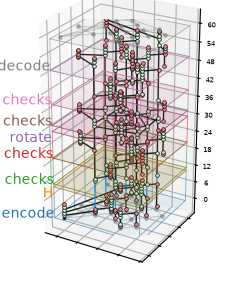

In [4]:
fig = draw_program_3d(p, l1, show_phases=False, spider_size=7, figsize=(3.0, 2.9), space_ticks=False)
ax = fig.axes[0]
ax.set_box_aspect((1, 1, 2.0), zoom=1.25)         # time stretched, so the eight blocks spread out
ax.set_position([0.26, -0.08, 0.72, 1.16])        # fill the figure, with room on the left for the block names
for label in ax.texts:                            # the block names, left of their slabs
    label.set_fontsize(10)
    label.set_horizontalalignment('right')
    if label.get_text() in ('H', 'rotate'):       # short blocks: the name hangs below, clear of the next one
        label.set_verticalalignment('top')
ax.set_xlabel(''); ax.set_ylabel(''); ax.set_zlabel('')
ax.tick_params(labelsize=5, pad=-2)
fig.savefig('figures/fold_h_figure/fth-level0-3d.pdf')          # not bbox_inches='tight': it leaves out the 3D text
fig

**What you see.** The eight blocks as slabs, named in their colours. The Z ancillas and qubit 18 have no wire before the block that first uses them.

## (b) The same program as one ZX-diagram

**What we do.** `draw_program` at level `l1`: time going right, each block on a background of its colour (the colours of panel (a)), with `time_scale=2` so that spiders on one wire and one tick do not touch. The block names are left out (panel (a) names the blocks in the same colours). The picture gets the drawing's own shape, so that `block_spans` gives where each block starts and ends as a fraction of its width: where the paper's figure joins (b) to (c).

width / height: 5.988; each block as a fraction of the width:
  encode    0.0050 0.1865
  H         0.1865 0.2030
  Z checks  0.2030 0.3515
  X checks  0.3515 0.5000
  rotate    0.5000 0.5330
  Z checks  0.5330 0.6485
  X checks  0.6485 0.8300
  decode    0.8300 0.9950


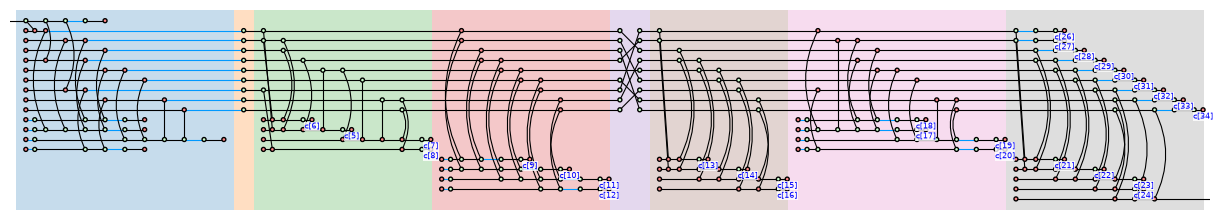

In [5]:
STRETCH = 2.0
fig = draw_program(p, l1, show_time=False, time_scale=STRETCH, alpha=0.25, label_size=6, figsize=(12, 3))
ax = fig.axes[0]
for t in list(ax.texts):                          # the block names: (a) names the blocks in the same colours
    if t.get_text() in {name for _a, _b, name, _role in G8}:
        t.remove()
start = min(p.stage(s).ticks[0] for s in range(p.num_stages))
end = max(p.stage(s).ticks[1] for s in range(p.num_stages))
ax.set_xlim((start - 0.8) * STRETCH, (end + 0.8) * STRETCH)   # all ticks, and the ends of the input and output wires
x0, x1 = ax.get_xlim()
y0, y1 = ax.get_ylim()
fig.set_size_inches(12, 12 * (y1 - y0) / (x1 - x0))   # the figure has the drawing's shape, so the axes fill it
ax.set_position([0, 0, 1, 1])
fig.savefig('figures/fold_h_figure/fth-zx.pdf')
fig.savefig('figures/fold_h_figure/fth-zx.png', dpi=200, facecolor='white')
print("width / height: {:.3f}; each block as a fraction of the width:".format((x1 - x0) / (y1 - y0)))
for label, ranges in block_spans(p, l1, time_scale=STRETCH):
    print("  {:9s} {}".format(label, "  ".join("{:.4f} {:.4f}".format((a - x0) / (x1 - x0), (b - x0) / (x1 - x0))
                                                for a, b in ranges)))
fig

**What you see.** One background colour per block, the colours of panel (a). The first block (blue) has no result labels: it post-selects. The wires of the turn cross inside its own strip, between the identities on their old and new places. The printed lines are the block edges the paper uses.

## (c) Each block in its normal form

**What we do.** The same program with each stage a block of its own, each rewritten into its normal form with one spider per check (`gpf.build(..., rewrite='gpf_checks')`; H and the turn are left as they are), drawn on the chip seen from just off the top (`draw_blocks_3d`). Then each picture is saved on its own (`save_panels`), for the paper to place under its block.

Level 1 (8 blocks), rewritten:
  Block 0: encode + X checks (1 children): 57 spiders -> 14 after rewrite gpf_checks
  Block 1: transversal H (1 children): 9 spiders -> 9 after no rewrite
  Block 2: Z checks (code 2) (1 children): 36 spiders -> 22 after rewrite x-z gpf_checks
  Block 3: X checks (code 2) (1 children): 44 spiders -> 22 after rewrite gpf_checks
  Block 4: rotate 90° (1 children): 17 spiders -> 17 after no rewrite
  Block 5: Z checks (1 children): 36 spiders -> 22 after rewrite x-z gpf_checks
  Block 6: X checks (1 children): 44 spiders -> 22 after rewrite gpf_checks
  Block 7: Z checks + decode (1 children): 70 spiders -> 14 after rewrite gpf_checks


panel 0: 1.43 x 1.35 in
panel 1: 1.15 x 1.09 in
panel 2: 1.10 x 1.72 in
panel 3: 1.86 x 1.29 in
panel 4: 1.06 x 1.09 in
panel 5: 1.92 x 1.23 in
panel 6: 1.10 x 1.67 in
panel 7: 1.92 x 1.74 in


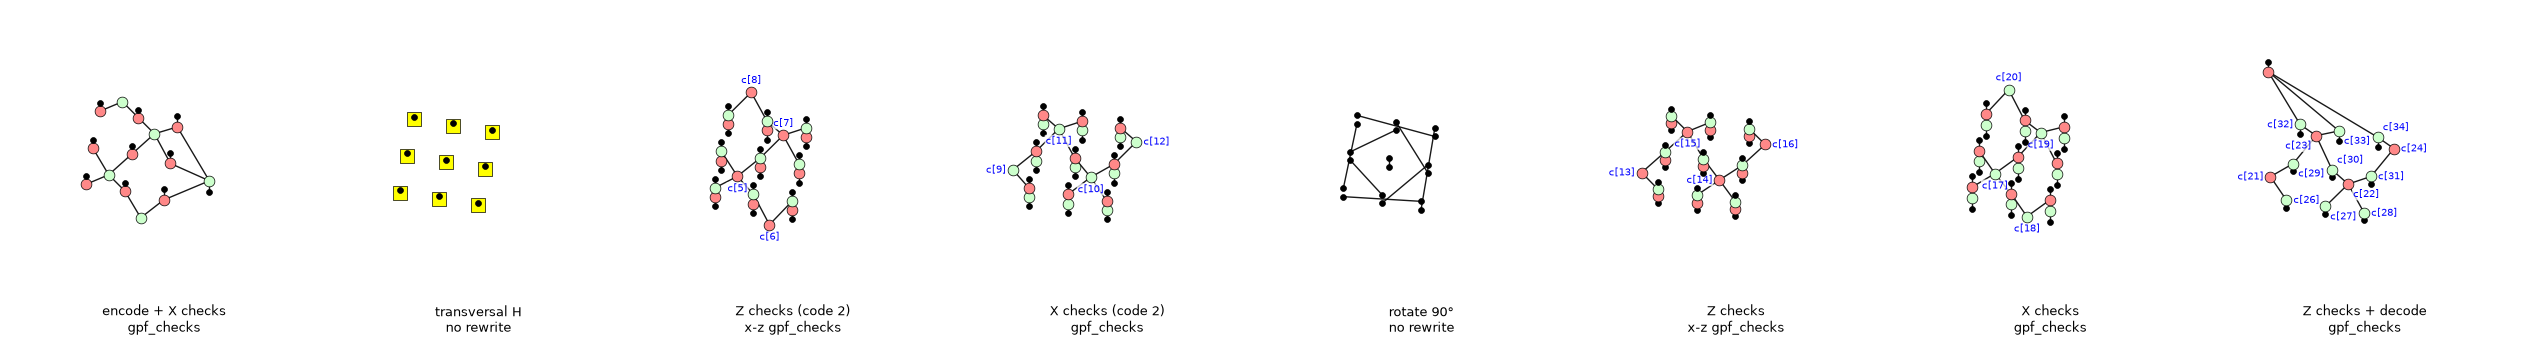

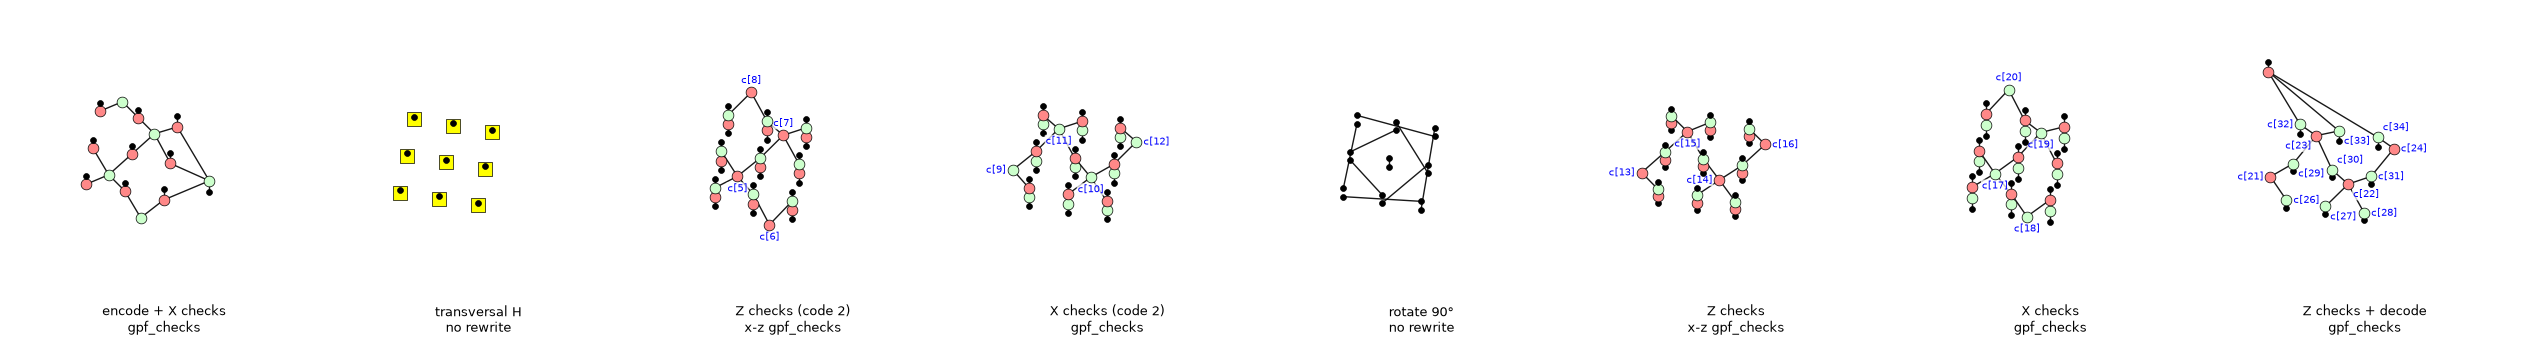

In [6]:
pc, level_c = gpf.build(False, rewrite='gpf_checks', places={0: (4, 2), 14: (0.5, 1.5)},
                        post_select_encoder=True, cross_inside=True)
print(pc.describe_reduced(level_c))
fig = draw_blocks_3d(pc, level_c, view=(70, -80), time_scale=0.5, by_outcomes=True, crossing_wires=True,
                     min_stub=0.25, columns=8, phases_beside=True, hadamard_boxes=True, finish=False)
for k, (w, h) in enumerate(save_panels(fig, 'figures/fold_h_figure/fth-c-gpf-{k}.{ext}', formats=('pdf', 'png'))):
    print("panel {}: {:.2f} x {:.2f} in".format(k, w, h))
fig

**What you see.** From left to right: the encoder (post-selected: each check one spider over its ancilla, with no result); the nine Hadamards; the round in code 2, its Z checks and then its X checks, with results `c[5]` to `c[12]`; the turn, its wires crossing; the round in code 1, with `c[13]` to `c[20]`; the decoder, with its results `c[21]` to `c[34]`.

## (d) The whole program, reduced

**What we do.** The normal form of the whole program (`reduced_block(L3, 0)`), its phases written modulo the detectors (`phases_modulo`), drawn with time going up as in panel (a).

spiders: 2 | edges: ['Hadamard', 'plain', 'plain']
  when c[29] + c[26] + c[32] = 0: H, then nothing
  when c[29] + c[26] + c[32] = 1: H, then Z


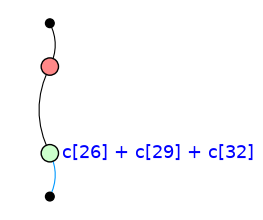

In [7]:
reduced = p.reduced_block(L3, 0)
up = phases_modulo(reduced.graph, reduced.detectors)
print("spiders:", sum(1 for v in up.vertices() if up.type(v) != VertexType.BOUNDARY),
      "| edges:", ['Hadamard' if up.edge_type(e) == EdgeType.HADAMARD else 'plain' for e in up.edges()])
for b in action.branches():
    print("  {}: {}, then {}".format(b.when(), b.operation, b.correction or 'nothing'))
for v in up.vertices():                           # time going up, as in panel (a)
    up.set_qubit(v, -up.row(v))
    up.set_row(v, 0)
fig = draw_graph(up, time_axis=False, show_time=False, label_size=13, label_side='right', figsize=(1.0, 2.6))
fig.savefig('figures/fold_h_figure/fth-whole-reduced-up.pdf', bbox_inches='tight')
fig

**What you see.** Two spiders: a Hadamard edge (blue) from the input, then a green spider with phase `(c[26] + c[29] + c[32])π`, a Z when that parity is 1.